# Текущий контроль 5–6 (реализация): качество красного вина методом kNN

**Задание.** По данным `winequality-red.csv` определить качество вина методом $k$ ближайших соседей, разделить данные на обучающую и тестовую части, построить матрицу ошибок и сделать выводы.

Здесь `quality` сохраняется как исходная **оценка от 3 до 8**. Это задача многоклассовой классификации: модель выбирает один из шести классов. В предыдущей работе 3–4 та же колонка превращалась в два класса; здесь такого преобразования нет.

## 1. Как работает kNN

Для каждого нового вина сравниваем его признаки с обучающими примерами и находим $k$ ближайших. Модель выбирает оценку, за которую проголосовало больше соседей:

$$\hat y(\mathbf{x})=\operatorname{mode}\{y_i: i\in N_k(\mathbf{x})\},$$

где $N_k(\mathbf{x})$ — индексы $k$ ближайших обучающих вин. В этой работе используется евклидово расстояние:

$$d(\mathbf{x},\mathbf{z})=\sqrt{\sum_{j=1}^{11}(x_j-z_j)^2}.$$

Признаки измеряются в разных единицах: например, `density` близка к 1, а `total sulfur dioxide` может быть больше 100. Без масштабирования признаки с большим числовым разбросом сильнее влияют на расстояние. Поэтому каждый признак стандартизуется:

$$x'_j=\frac{x_j-\mu_j}{s_j},$$

где среднее $\mu_j$ и стандартное отклонение $s_j$ вычисляются **только на обучающей части**. `Pipeline` применит те же параметры к тестовой части и к данным внутри кросс-валидации.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
)
from sklearn.model_selection import GridSearchCV, StratifiedKFold, train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

plt.style.use('seaborn-v0_8-whitegrid')

## 2. Загрузка и проверка данных

Каждая строка описывает одно вино: 11 физико-химических признаков составляют $X$, а колонка `quality` — правильный ответ $y$. В исходном файле есть полностью одинаковые строки. Удаляем их **до разделения**, чтобы одинаковое вино не оказалось одновременно в train и test.

In [2]:
data_file = Path('winequality-red.csv')
if not data_file.is_file():
    raise FileNotFoundError(
        'Поместите winequality-red.csv рядом с ноутбуком и запустите его из корня проекта.'
    )

wine_raw = pd.read_csv(data_file)
if 'quality' not in wine_raw.columns:
    raise ValueError('В CSV отсутствует целевая колонка quality.')
if wine_raw.isna().any().any():
    raise ValueError('В CSV есть пропуски: перед обучением нужна их обработка.')

duplicate_count = int(wine_raw.duplicated().sum())
wine = wine_raw.drop_duplicates().reset_index(drop=True)
X = wine.drop(columns='quality')
y = wine['quality']
classes = np.sort(y.unique())

print(f'Исходных строк: {len(wine_raw)}')
print(f'Полных повторов: {duplicate_count}')
print(f'После удаления повторов: {len(wine)}')
print(f'Признаков: {X.shape[1]}; классы: {classes.tolist()}')
display(wine.head())
display(y.value_counts().sort_index().rename('Количество вин').to_frame())

Исходных строк: 1599
Полных повторов: 240
После удаления повторов: 1359
Признаков: 11; классы: [3, 4, 5, 6, 7, 8]


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.66,0.00,1.8,0.075,13.0,40.0,0.9978,3.51,0.56,9.4,5


,Количество вин
quality,
3,10
4,53
5,577
6,535
7,167
8,17


Классы распределены неравномерно: оценки 5 и 6 встречаются чаще, чем 3 и 8. Поэтому далее показываем не только общую долю верных ответов (`accuracy`), но и **macro F1** — среднее качество по классам, где редкие классы имеют такой же вес, как частые.

## 3. Обучающая и тестовая части

25% уникальных вин откладываем для итоговой проверки. `stratify=y` сохраняет приблизительно одинаковые доли оценок в обеих частях. `random_state=42` делает результат воспроизводимым. Тестовые вина не участвуют ни в масштабировании, ни в выборе $k$.

In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=42
)

print(f'Обучающих вин: {len(X_train)}; тестовых вин: {len(X_test)}')
print('Классы в обучающей части:')
display(y_train.value_counts().sort_index().rename('train').to_frame())
print('Классы в тестовой части:')
display(y_test.value_counts().sort_index().rename('test').to_frame())

Обучающих вин: 1019; тестовых вин: 340
Классы в обучающей части:


,train
quality,
3,7
4,40
5,433
6,401
7,125
8,13


Классы в тестовой части:


,test
quality,
3,3
4,13
5,144
6,134
7,42
8,4


## 4. Масштабирование и выбор числа соседей

Проверяем нечётные значения $k$ от 1 до 31. Для каждого варианта проводим пятиблочную стратифицированную кросс-валидацию **только на train**. На каждом разбиении `StandardScaler` обучается заново на своей обучающей части, поэтому валидационная часть не влияет на его параметры.

В качестве критерия выбора используем `f1_macro`:

$$F1_c=\frac{2P_cR_c}{P_c+R_c},\qquad F1_{macro}=\frac{1}{6}\sum_{c=3}^{8}F1_c,$$

где $P_c$ — точность ответов класса $c$, $R_c$ — полнота класса $c$. Если знаменатель равен нулю, библиотека считает соответствующий F1 нулём.

,k,macro F1 на CV
0,1,0.299
1,3,0.255
2,5,0.269
3,7,0.276
4,9,0.269
5,11,0.271
6,13,0.270
7,15,0.273
8,17,0.266
9,19,0.274


Лучшее k = 1
Средний macro F1 на CV = 0.299


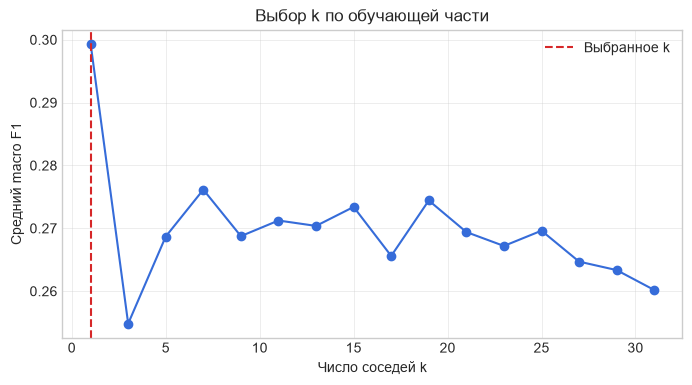

In [4]:
# Pipeline помещает преобразование и классификатор в одну модель.
# Это защищает от утечки данных при кросс-валидации.
pipeline = make_pipeline(StandardScaler(), KNeighborsClassifier())
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

search = GridSearchCV(
    estimator=pipeline,
    param_grid={'kneighborsclassifier__n_neighbors': list(range(1, 32, 2))},
    scoring='f1_macro',
    cv=cv,
    n_jobs=1,
)
search.fit(X_train, y_train)

cv_results = pd.DataFrame({
    'k': search.cv_results_['param_kneighborsclassifier__n_neighbors'].astype(int),
    'macro F1 на CV': search.cv_results_['mean_test_score'],
}).sort_values('k')
display(cv_results.round(3))
print(f'Лучшее k = {search.best_params_["kneighborsclassifier__n_neighbors"]}')
print(f'Средний macro F1 на CV = {search.best_score_:.3f}')

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(cv_results['k'], cv_results['macro F1 на CV'], marker='o')
ax.axvline(search.best_params_['kneighborsclassifier__n_neighbors'],
           color='tab:red', linestyle='--', label='Выбранное k')
ax.set(xlabel='Число соседей k', ylabel='Средний macro F1',
       title='Выбор k по обучающей части')
ax.legend()
plt.show()

## 5. Проверка на отложенных винах

`GridSearchCV` после выбора $k$ заново обучает лучшую модель на всей обучающей части. Тест применяется один раз для итоговой оценки. Для ориентира сравним kNN с простым правилом `most_frequent`: всегда предсказывать самый распространённый обучающий класс.

$$Accuracy=\frac{\text{число верных прогнозов}}{\text{число всех тестовых вин}}.$$

In [5]:
knn = search.best_estimator_
y_pred = knn.predict(X_test)

baseline = DummyClassifier(strategy='most_frequent')
baseline.fit(X_train, y_train)
y_baseline = baseline.predict(X_test)

metrics = pd.DataFrame({
    'Модель': ['Всегда частый класс', 'kNN'],
    'Accuracy': [accuracy_score(y_test, y_baseline), accuracy_score(y_test, y_pred)],
    'Macro F1': [
        f1_score(y_test, y_baseline, average='macro', zero_division=0),
        f1_score(y_test, y_pred, average='macro', zero_division=0),
    ],
    'Weighted F1': [
        f1_score(y_test, y_baseline, average='weighted', zero_division=0),
        f1_score(y_test, y_pred, average='weighted', zero_division=0),
    ],
})
display(metrics.round(3))
print('Отчёт kNN по каждому классу:')
print(classification_report(y_test, y_pred, labels=classes, zero_division=0))

,Модель,Accuracy,Macro F1,Weighted F1
0,Всегда частый класс,0.424,0.099,0.252
1,kNN,0.524,0.296,0.521


Отчёт kNN по каждому классу:
              precision    recall  f1-score   support

           3       0.00      0.00      0.00         3
           4       0.20      0.15      0.17        13
           5       0.62      0.56      0.59       144
           6       0.50      0.54      0.52       134
           7       0.45      0.55      0.49        42
           8       0.00      0.00      0.00         4

    accuracy                           0.52       340
   macro avg       0.29      0.30      0.30       340
weighted avg       0.52      0.52      0.52       340



## 6. Матрица ошибок

Элемент $C_{ij}$ — сколько вин с **реальной** оценкой $i$ получили **прогноз** $j$. Правильные ответы стоят на главной диагонали. Левая матрица показывает число вин; правая — долю внутри каждого реального класса. По правой матрице легче оценивать редкие классы, но для них результат менее устойчив из-за малого числа примеров.

Матрица ошибок (строки — реальные оценки, столбцы — прогнозы):


,3,4,5,6,7,8
3,0,1,1,1,0,0
4,0,2,5,6,0,0
5,1,6,80,49,8,0
6,0,1,41,73,18,1
7,0,0,2,16,23,1
8,0,0,0,2,2,0


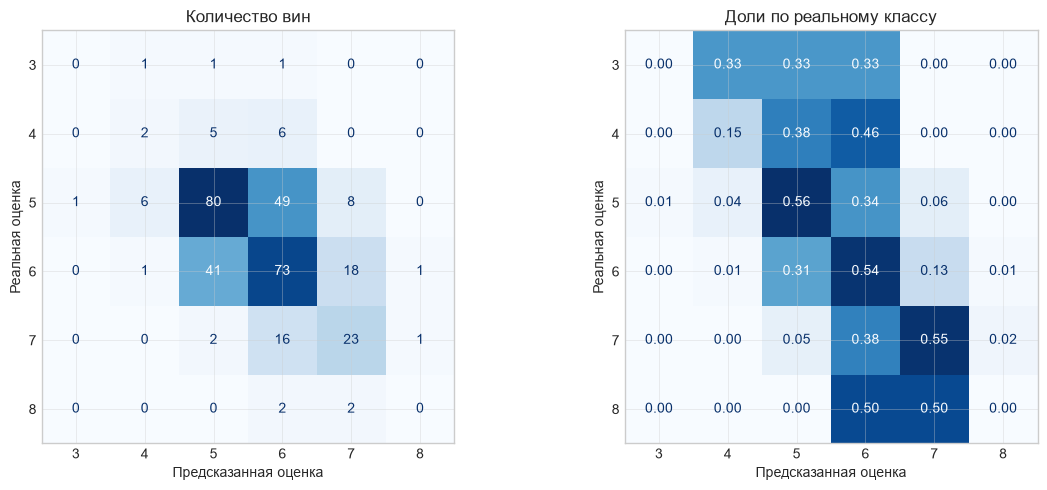

In [6]:
cm = confusion_matrix(y_test, y_pred, labels=classes)
cm_normalized = confusion_matrix(y_test, y_pred, labels=classes, normalize='true')

print('Матрица ошибок (строки — реальные оценки, столбцы — прогнозы):')
display(pd.DataFrame(cm, index=classes, columns=classes))

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
ConfusionMatrixDisplay(cm, display_labels=classes).plot(
    ax=axes[0], cmap='Blues', colorbar=False, values_format='d'
)
ConfusionMatrixDisplay(cm_normalized, display_labels=classes).plot(
    ax=axes[1], cmap='Blues', colorbar=False, values_format='.2f'
)
axes[0].set_title('Количество вин')
axes[1].set_title('Доли по реальному классу')
for ax in axes:
    ax.set_xlabel('Предсказанная оценка')
    ax.set_ylabel('Реальная оценка')
fig.tight_layout()
plt.show()

## 7. Выводы

После удаления 240 повторов осталось **1359 уникальных вин**. На 1019 обучающих винах кросс-валидация выбрала $k=1$. На 340 тестовых винах kNN правильно классифицировал **178 вин (52,4%)**; простое правило самого частого класса — **42,4%**. Однако `macro F1 = 0,296` показывает, что качество между оценками сильно различается.

Чаще всего модель путает соседние оценки **5 и 6**: 49 вин с реальной оценкой 5 получили прогноз 6, а 41 вино с оценкой 6 — прогноз 5. Оценки **3 и 8** в тесте не распознаны ни разу; их обучающих примеров очень мало. Поэтому общая accuracy не означает одинаково хорошего качества для всех оценок. Удаление повторов делает проверку строже и исключает совпадение идентичных вин в train и test.